In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader




In [5]:
# Load dataset
df = pd.read_csv("/content/drive/MyDrive/AI_ML/Datasets/adult.csv")



In [6]:
# Display first five rows
print(df.head())



   age  workclass  fnlwgt     education  educational-num      marital-status  \
0   25    Private  226802          11th                7       Never-married   
1   38    Private   89814       HS-grad                9  Married-civ-spouse   
2   28  Local-gov  336951    Assoc-acdm               12  Married-civ-spouse   
3   44    Private  160323  Some-college               10  Married-civ-spouse   
4   18          ?  103497  Some-college               10       Never-married   

          occupation relationship   race  gender  capital-gain  capital-loss  \
0  Machine-op-inspct    Own-child  Black    Male             0             0   
1    Farming-fishing      Husband  White    Male             0             0   
2    Protective-serv      Husband  White    Male             0             0   
3  Machine-op-inspct      Husband  Black    Male          7688             0   
4                  ?    Own-child  White  Female             0             0   

   hours-per-week native-country incom

In [7]:
# Dataset shape
print("Shape:", df.shape)




Shape: (48842, 15)


In [8]:
# Column names and data types
print(df.info())



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   age              48842 non-null  int64 
 1   workclass        48842 non-null  object
 2   fnlwgt           48842 non-null  int64 
 3   education        48842 non-null  object
 4   educational-num  48842 non-null  int64 
 5   marital-status   48842 non-null  object
 6   occupation       48842 non-null  object
 7   relationship     48842 non-null  object
 8   race             48842 non-null  object
 9   gender           48842 non-null  object
 10  capital-gain     48842 non-null  int64 
 11  capital-loss     48842 non-null  int64 
 12  hours-per-week   48842 non-null  int64 
 13  native-country   48842 non-null  object
 14  income           48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB
None


In [9]:
# Statistical summary
print(df.describe())



                age        fnlwgt  educational-num  capital-gain  \
count  48842.000000  4.884200e+04     48842.000000  48842.000000   
mean      38.643585  1.896641e+05        10.078089   1079.067626   
std       13.710510  1.056040e+05         2.570973   7452.019058   
min       17.000000  1.228500e+04         1.000000      0.000000   
25%       28.000000  1.175505e+05         9.000000      0.000000   
50%       37.000000  1.781445e+05        10.000000      0.000000   
75%       48.000000  2.376420e+05        12.000000      0.000000   
max       90.000000  1.490400e+06        16.000000  99999.000000   

       capital-loss  hours-per-week  
count  48842.000000    48842.000000  
mean      87.502314       40.422382  
std      403.004552       12.391444  
min        0.000000        1.000000  
25%        0.000000       40.000000  
50%        0.000000       40.000000  
75%        0.000000       45.000000  
max     4356.000000       99.000000  


In [10]:
# Check missing values
print(df.isnull().sum())



age                0
workclass          0
fnlwgt             0
education          0
educational-num    0
marital-status     0
occupation         0
relationship       0
race               0
gender             0
capital-gain       0
capital-loss       0
hours-per-week     0
native-country     0
income             0
dtype: int64


In [11]:
# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 52


In [12]:
# Check target distribution
print(df["income"].value_counts())

income
<=50K    37155
>50K     11687
Name: count, dtype: int64


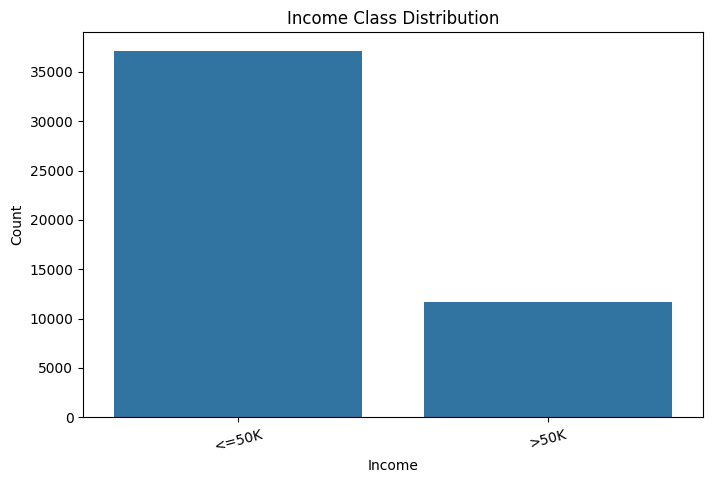

In [13]:

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="income")

plt.title("Income Class Distribution")
plt.xlabel("Income")
plt.ylabel("Count")
plt.xticks(rotation=15)
plt.show()


### Data Cleaning and Preprocessing

In [14]:
# Replace '?'
df.replace('?', np.nan, inplace=True)

# Check missing values again
print(df.isnull().sum())

age                   0
workclass          2799
fnlwgt                0
education             0
educational-num       0
marital-status        0
occupation         2809
relationship          0
race                  0
gender                0
capital-gain          0
capital-loss          0
hours-per-week        0
native-country      857
income                0
dtype: int64


In [15]:
# Remove spaces from text columns
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

# Standardize income labels
df['income'] = df['income'].str.replace('.', '', regex=False)

# Check target values
print(df['income'].value_counts())

income
<=50K    37155
>50K     11687
Name: count, dtype: int64


### Separate X and y

In [16]:
X = df.drop('income', axis=1)
y = df['income']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (48842, 14)
Target shape: (48842,)


In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (39073, 14)
Testing features: (9769, 14)


### Preprocess numerical and categorical columns

In [20]:
# Identify numerical and categorical columns
num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X_train.select_dtypes(include=['object']).columns

print("Numerical columns:", list(num_cols))
print("Categorical columns:", list(cat_cols))

Numerical columns: ['age', 'fnlwgt', 'educational-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Categorical columns: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'gender', 'native-country']


# Handling Missing Values

In [21]:

# Numerical missing values
num_imputer = SimpleImputer(strategy='median')

X_train[num_cols] = num_imputer.fit_transform(X_train[num_cols])
X_test[num_cols] = num_imputer.transform(X_test[num_cols])

# Categorical missing values
cat_imputer = SimpleImputer(strategy='most_frequent')

X_train[cat_cols] = cat_imputer.fit_transform(X_train[cat_cols])
X_test[cat_cols] = cat_imputer.transform(X_test[cat_cols])

print("Missing values in training data:", X_train.isnull().sum().sum())
print("Missing values in testing data:", X_test.isnull().sum().sum())

Missing values in training data: 0
Missing values in testing data: 0


In [22]:


encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

# Fit on training data
X_train_encoded = encoder.fit_transform(X_train[cat_cols])

# Transform testing data
X_test_encoded = encoder.transform(X_test[cat_cols])

# Convert to DataFrames
X_train_encoded = pd.DataFrame(
    X_train_encoded,
    columns=encoder.get_feature_names_out(cat_cols),
    index=X_train.index
)

X_test_encoded = pd.DataFrame(
    X_test_encoded,
    columns=encoder.get_feature_names_out(cat_cols),
    index=X_test.index
)

# Remove original categorical columns and combine encoded columns
X_train = pd.concat([X_train.drop(columns=cat_cols), X_train_encoded], axis=1)
X_test = pd.concat([X_test.drop(columns=cat_cols), X_test_encoded], axis=1)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (39073, 105)
Testing shape: (9769, 105)


### Scale numerical features

In [24]:
scaler = StandardScaler()

X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

print(X_train.head())

            age    fnlwgt  educational-num  capital-gain  capital-loss  \
34342  2.351033 -1.068107        -0.419324     -0.144218     -0.220137   
18559 -1.579144  1.334110        -1.584910     -0.144218     -0.220137   
12477 -0.851333 -0.934892        -0.419324     -0.144218     -0.220137   
560    0.313164 -0.608420        -0.419324     -0.144218     -0.220137   
3427  -0.560209 -0.490454         1.134791     -0.144218     -0.220137   

       hours-per-week  workclass_Federal-gov  workclass_Local-gov  \
34342       -1.889257                    0.0                  0.0   
18559       -2.453045                    0.0                  0.0   
12477       -0.036809                    0.0                  0.0   
560         -0.036809                    0.0                  0.0   
3427        -0.036809                    0.0                  0.0   

       workclass_Never-worked  workclass_Private  ...  \
34342                     0.0                1.0  ...   
18559                     

In [26]:
#Convert the processed data to NumPy arrays
X_train_np = X_train.to_numpy(dtype='float32')
X_test_np = X_test.to_numpy(dtype='float32')

y_train_np = y_train.to_numpy(dtype='float32')
y_test_np = y_test.to_numpy(dtype='float32')

print("X_train:", X_train_np.shape)
print("X_test:", X_test_np.shape)

X_train: (39073, 105)
X_test: (9769, 105)


### Build the model

In [28]:
tf_model = Sequential([
    Input(shape=(X_train_np.shape[1],)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])

tf_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         6,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,897 (34.75 KB)

 Trainable params: 8,897 (34.75 KB)

 Non-trainable params: 0 (0.00 B)

In [29]:
tf_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

### Train the model

In [30]:
history = tf_model.fit(
    X_train_np,
    y_train_np,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/20
977/977 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.8441 - loss: 0.3330 - val_accuracy: 0.8484 - val_loss: 0.3195
Epoch 2/20
977/977 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.8551 - loss: 0.3082 - val_accuracy: 0.8550 - val_loss: 0.3163
Epoch 3/20
977/977 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8576 - loss: 0.3030 - val_accuracy: 0.8559 - val_loss: 0.3187
Epoch 4/20
977/977 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8601 - loss: 0.2991 - val_accuracy: 0.8564 - val_loss: 0.3200
Epoch 5/20
977/977 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8617 - loss: 0.2955 - val_accuracy: 0.8572 - val_loss: 0.3207
Epoch 6/20
977/977 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8636 - loss: 0.2927 - val_accuracy: 0.8571 - val_loss: 0.3231
Epoch 7/20
977/977 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8642 - loss: 0.2897 - val_accuracy: 0.8568 - val_loss: 0.3237
Epoch 8/20
977/977 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.8666 - loss: 0.2872 - val_accuracy: 0

### Model Evaluation

In [31]:
test_loss, test_accuracy = tf_model.evaluate(
    X_test_np,
    y_test_np,
    verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

Test Loss: 0.33094528317451477
Test Accuracy: 0.8550516963005066


Accuracy: 0.8550516941345071

Classification Report:
              precision    recall  f1-score   support

         0.0       0.89      0.93      0.91      7431
         1.0       0.73      0.62      0.67      2338

    accuracy                           0.86      9769
   macro avg       0.81      0.77      0.79      9769
weighted avg       0.85      0.86      0.85      9769



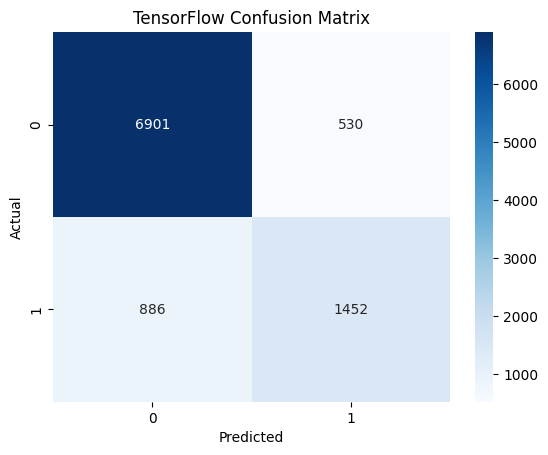

In [32]:
y_prob_tf = tf_model.predict(X_test_np, verbose=0).ravel()

y_pred_tf = (y_prob_tf >= 0.5).astype(int)

print("Accuracy:", accuracy_score(y_test_np, y_pred_tf))
print("\nClassification Report:")
print(classification_report(y_test_np, y_pred_tf, zero_division=0))

cm_tf = confusion_matrix(y_test_np, y_pred_tf)

sns.heatmap(cm_tf, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("TensorFlow Confusion Matrix")
plt.show()

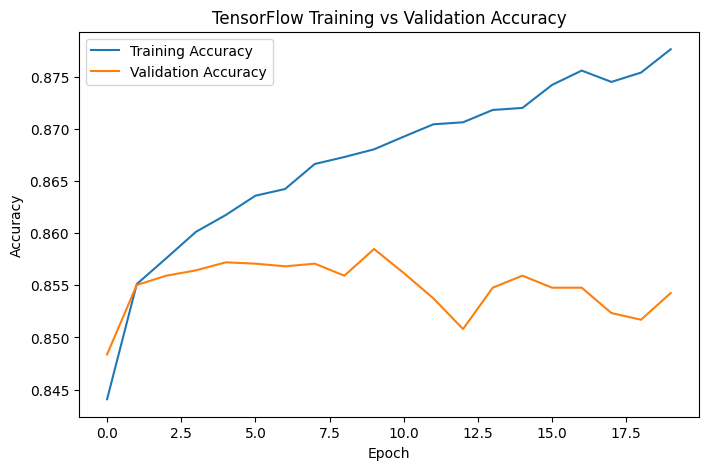

In [33]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("TensorFlow Training vs Validation Accuracy")
plt.legend()
plt.show()

## PyTorch Implementation

In [35]:
X_train_tensor = torch.tensor(X_train_np, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_np, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train_np, dtype=torch.float32).view(-1, 1)
y_test_tensor = torch.tensor(y_test_np, dtype=torch.float32).view(-1, 1)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

In [36]:
class IncomeModel(nn.Module):
    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)


torch_model = IncomeModel(X_train_np.shape[1])

print(torch_model)

IncomeModel(
  (network): Sequential(
    (0): Linear(in_features=105, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [ ]:
# loss function and optimizer

In [37]:
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(torch_model.parameters(), lr=0.001)

### Model Training

In [38]:
epochs = 20

for epoch in range(epochs):
    torch_model.train()
    total_loss = 0

    for X_batch, y_batch in train_loader:
        # Forward pass
        outputs = torch_model(X_batch)
        loss = criterion(outputs, y_batch)

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * X_batch.size(0)

    avg_loss = total_loss / len(train_dataset)

    print(
        f"Epoch [{epoch+1}/{epochs}], "
        f"Loss: {avg_loss:.4f}"
    )

Epoch [1/20], Loss: 0.3311
Epoch [2/20], Loss: 0.3088
Epoch [3/20], Loss: 0.3052
Epoch [4/20], Loss: 0.3025
Epoch [5/20], Loss: 0.2995
Epoch [6/20], Loss: 0.2976
Epoch [7/20], Loss: 0.2958
Epoch [8/20], Loss: 0.2932
Epoch [9/20], Loss: 0.2919
Epoch [10/20], Loss: 0.2894
Epoch [11/20], Loss: 0.2878
Epoch [12/20], Loss: 0.2862
Epoch [13/20], Loss: 0.2843
Epoch [14/20], Loss: 0.2828
Epoch [15/20], Loss: 0.2810
Epoch [16/20], Loss: 0.2794
Epoch [17/20], Loss: 0.2775
Epoch [18/20], Loss: 0.2760
Epoch [19/20], Loss: 0.2749
Epoch [20/20], Loss: 0.2728


### Model evaluation

PyTorch Accuracy: 0.8584297266864571

Classification Report:
              precision    recall  f1-score   support

         0.0       0.90      0.92      0.91      7431
         1.0       0.72      0.67      0.69      2338

    accuracy                           0.86      9769
   macro avg       0.81      0.79      0.80      9769
weighted avg       0.86      0.86      0.86      9769



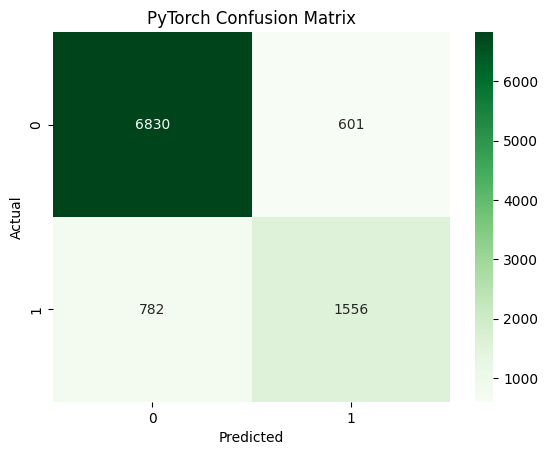

In [40]:
torch_model.eval()

with torch.no_grad():
    logits = torch_model(X_test_tensor)
    y_prob_torch = torch.sigmoid(logits).numpy().ravel()

y_pred_torch = (y_prob_torch >= 0.5).astype(int)

print("PyTorch Accuracy:",
      accuracy_score(y_test_np, y_pred_torch))

print("\nClassification Report:")
print(classification_report(
    y_test_np,
    y_pred_torch,
    zero_division=0
))

cm_torch = confusion_matrix(y_test_np, y_pred_torch)

sns.heatmap(cm_torch, annot=True, fmt='d', cmap='Greens')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("PyTorch Confusion Matrix")
plt.show()

### Compare TensorFlow and PyTorch

In [41]:
tf_accuracy = accuracy_score(y_test_np, y_pred_tf)
torch_accuracy = accuracy_score(y_test_np, y_pred_torch)

comparison = pd.DataFrame({
    "Model": ["TensorFlow", "PyTorch"],
    "Accuracy": [tf_accuracy, torch_accuracy]
})

print(comparison)

        Model  Accuracy
0  TensorFlow  0.855052
1     PyTorch  0.858430


# Optuna Hyperparameter Tuning

In [42]:
%pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 270.4/270.4 kB 11.3 MB/s eta 0:00:00


In [43]:


import optuna


from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# 1. Split training data into train and validation
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train_np,
    y_train_np,
    test_size=0.2,
    random_state=42,
    stratify=y_train_np
)

# 2. Define Optuna objective function
def objective(trial):

    n_layers = trial.suggest_int("n_layers", 1, 3)
    n_units = trial.suggest_categorical(
        "n_units", [32, 64, 128]
    )
    learning_rate = trial.suggest_float(
        "learning_rate", 1e-4, 1e-2, log=True
    )
    batch_size = trial.suggest_categorical(
        "batch_size", [32, 64, 128]
    )
    dropout = trial.suggest_float("dropout", 0.0, 0.4)

    torch.manual_seed(42)

    # Build neural network
    layers = []
    input_size = X_subtrain.shape[1]

    for _ in range(n_layers):
        layers.append(nn.Linear(input_size, n_units))
        layers.append(nn.ReLU())

        if dropout > 0:
            layers.append(nn.Dropout(dropout))

        input_size = n_units

    layers.append(nn.Linear(input_size, 1))
    model = nn.Sequential(*layers)

    # Convert data to tensors
    Xtr = torch.tensor(X_subtrain, dtype=torch.float32)
    ytr = torch.tensor(
        y_subtrain, dtype=torch.float32
    ).reshape(-1, 1)

    Xv = torch.tensor(X_val, dtype=torch.float32)
    yv = torch.tensor(
        y_val, dtype=torch.float32
    ).reshape(-1, 1)

    loader = DataLoader(
        TensorDataset(Xtr, ytr),
        batch_size=batch_size,
        shuffle=True
    )

    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(
        model.parameters(), lr=learning_rate
    )

    # Train model
    for epoch in range(10):
        model.train()

        for xb, yb in loader:
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()

    # Evaluate on validation data
    model.eval()

    with torch.no_grad():
        probabilities = torch.sigmoid(model(Xv)).numpy().ravel()

    predictions = (probabilities >= 0.5).astype(int)

    # F1 is more informative for an imbalanced dataset
    return f1_score(y_val, predictions, zero_division=0)


# 3. Run Optuna
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=15)

print("\nBest validation F1-score:", study.best_value)
print("Best hyperparameters:", study.best_params)

# 4. Build the final tuned model
best = study.best_params

torch.manual_seed(42)

layers = []
input_size = X_train_np.shape[1]

for _ in range(best["n_layers"]):
    layers.append(nn.Linear(input_size, best["n_units"]))
    layers.append(nn.ReLU())

    if best["dropout"] > 0:
        layers.append(nn.Dropout(best["dropout"]))

    input_size = best["n_units"]

layers.append(nn.Linear(input_size, 1))
tuned_model = nn.Sequential(*layers)

# Prepare complete training data
Xtr = torch.tensor(X_train_np, dtype=torch.float32)
ytr = torch.tensor(
    y_train_np, dtype=torch.float32
).reshape(-1, 1)

Xte = torch.tensor(X_test_np, dtype=torch.float32)

loader = DataLoader(
    TensorDataset(Xtr, ytr),
    batch_size=best["batch_size"],
    shuffle=True
)

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(
    tuned_model.parameters(),
    lr=best["learning_rate"]
)

# Train final model
for epoch in range(20):
    tuned_model.train()

    for xb, yb in loader:
        optimizer.zero_grad()
        loss = criterion(tuned_model(xb), yb)
        loss.backward()
        optimizer.step()

# 5. Final test evaluation
tuned_model.eval()

with torch.no_grad():
    tuned_prob = torch.sigmoid(tuned_model(Xte)).numpy().ravel()

y_pred_tuned = (tuned_prob >= 0.5).astype(int)

print("\nTUNED PYTORCH CLASSIFICATION REPORT")
print(classification_report(
    y_test_np, y_pred_tuned, zero_division=0
))

# 6. Compare all models
results = pd.DataFrame({
    "Model": ["TensorFlow", "PyTorch", "Tuned PyTorch"],
    "Accuracy": [
        accuracy_score(y_test_np, y_pred_tf),
        accuracy_score(y_test_np, y_pred_torch),
        accuracy_score(y_test_np, y_pred_tuned)
    ],
    "Precision": [
        precision_score(y_test_np, y_pred_tf, zero_division=0),
        precision_score(y_test_np, y_pred_torch, zero_division=0),
        precision_score(y_test_np, y_pred_tuned, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test_np, y_pred_tf, zero_division=0),
        recall_score(y_test_np, y_pred_torch, zero_division=0),
        recall_score(y_test_np, y_pred_tuned, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test_np, y_pred_tf, zero_division=0),
        f1_score(y_test_np, y_pred_torch, zero_division=0),
        f1_score(y_test_np, y_pred_tuned, zero_division=0)
    ]
})

print("\nFINAL MODEL COMPARISON")
print(results.round(4).to_string(index=False))


[I 2026-10-22 16:52:56,759] A new study created in memory with name: no-name-e5c61275-fbeb-4b7b-af26-63ee361c34b8
[I 2026-10-22 16:53:36,049] Trial 0 finished with value: 0.6517133956386293 and parameters: {'n_layers': 3, 'n_units': 32, 'learning_rate': 0.003629031332294922, 'batch_size': 64, 'dropout': 0.37547139529145795}. Best is trial 0 with value: 0.6517133956386293.
[I 2026-10-22 16:54:05,791] Trial 1 finished with value: 0.6654589371980676 and parameters: {'n_layers': 2, 'n_units': 64, 'learning_rate': 0.0012471770284947653, 'batch_size': 32, 'dropout': 0.1855064533165338}. Best is trial 1 with value: 0.6654589371980676.
[I 2026-10-22 16:54:20,697] Trial 2 finished with value: 0.6779463243873979 and parameters: {'n_layers': 3, 'n_units': 128, 'learning_rate': 0.003233721799483344, 'batch_size': 128, 'dropout': 0.1310749526062683}. Best is trial 2 with value: 0.6779463243873979.
[I 2026-10-22 16:54:29,804] Trial 3 finished with value: 0.6740139211136891 and parameters: {'n_layers


Best validation F1-score: 0.6909894969596462
Best hyperparameters: {'n_layers': 2, 'n_units': 32, 'learning_rate': 0.00316776968601129, 'batch_size': 128, 'dropout': 0.33139957056484126}

TUNED PYTORCH CLASSIFICATION REPORT
              precision    recall  f1-score   support

         0.0       0.89      0.94      0.91      7431
         1.0       0.76      0.61      0.68      2338

    accuracy                           0.86      9769
   macro avg       0.82      0.78      0.80      9769
weighted avg       0.86      0.86      0.86      9769


FINAL MODEL COMPARISON
        Model  Accuracy  Precision  Recall  F1 Score
   TensorFlow    0.8551     0.7326  0.6210    0.6722
      PyTorch    0.8584     0.7214  0.6655    0.6923
Tuned PyTorch    0.8611     0.7599  0.6133    0.6788


# Summary

 ### TensorFlow and PyTorch were used to build income prediction models, and their performance was compared using evaluation metrics. Optuna tuned the PyTorch model's hyperparameters, and the results showed whether tuning improved performance compared with the original models.